cell 0 - Lingkungan

In [1]:
import sys
import torch
import ultralytics
import pycocotools

print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("CUDA tersedia:", torch.cuda.is_available())
print("Ultralytics:", ultralytics.__version__)
print("pycocotools:", pycocotools.__file__)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM GiB:", round(torch.cuda.get_device_properties(0).total_memory / 2**30, 2))

Python: 3.12.6
PyTorch: 2.7.1+cu126
CUDA tersedia: True
Ultralytics: 8.4.213
pycocotools: c:\Users\Rafli\AppData\Local\Programs\Python\Python312\Lib\site-packages\pycocotools\__init__.py
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
VRAM GiB: 8.0


Cell 1 — Path checkpoint dan data

In [7]:
from pathlib import Path

# Temukan root workspace meskipun kernel dimulai dari reports/own_test_eval.
cwd = Path.cwd().resolve()
ROOT = next(
    (p for p in (cwd, *cwd.parents)
     if (p / "reports/own_test_eval/ground_truth_35.json").exists()),
    None,
)
if ROOT is None and cwd.name == "own_test_eval" and (cwd / "ground_truth_35.json").exists():
    ROOT = cwd.parents[1]
if ROOT is None:
    raise FileNotFoundError(
        f"Tidak menemukan root workspace dari {cwd}. "
        "Pastikan reports/own_test_eval/ground_truth_35.json tersedia."
    )

CHECKPOINTS = {
    "yolo26m_pretrained": ROOT / "local_runs/k35_m_pf0/weights/best.pt",
    "yolo26m_scratch": ROOT / "local_runs/k35_m_sf0_c3/weights/best.pt",
    "ecseg_l_pretrained": ROOT / "reports/ecseg_l_k35_ws/checkpoints/best_ecseg_l_k35_ws.pth",
    "ecseg_l_scratch": ROOT / "reports/ecseg_l_k35_scratch/checkpoints/best_ecseg_l_k35_scratch.pth",
}
EVAL = ROOT / "reports/own_test_eval"

for name, path in CHECKPOINTS.items():
    print(name, path.exists(), path)


yolo26m_pretrained True C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\local_runs\k35_m_pf0\weights\best.pt
yolo26m_scratch True C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\local_runs\k35_m_sf0_c3\weights\best.pt
ecseg_l_pretrained True C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\ecseg_l_k35_ws\checkpoints\best_ecseg_l_k35_ws.pth
ecseg_l_scratch True C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\ecseg_l_k35_scratch\checkpoints\best_ecseg_l_k35_scratch.pth


Cell 2 — Audit anotasi test set

In [8]:
import json
from collections import Counter

gt = json.loads((EVAL / "ground_truth_35.json").read_text(encoding="utf-8"))
classspace = json.loads((EVAL / "classspace.json").read_text(encoding="utf-8"))
thing_ids = {i for i, flag in enumerate(classspace["isthing"]) if flag}
thing_anns = [a for a in gt["annotations"] if a["category_id"] in thing_ids]
category_names = {c["id"]: c["name"] for c in gt["categories"]}
counts = Counter(a["category_id"] for a in thing_anns)

print("Images:", len(gt["images"]))
print("All annotations:", len(gt["annotations"]))
print("Thing annotations:", len(thing_anns))
print("Thing classes with GT:", {category_names[k]: v for k, v in sorted(counts.items())})


Images: 40
All annotations: 264
Thing annotations: 120
Thing classes with GT: {'bed': 22, 'blanket': 17, 'bottle': 9, 'cabinet-merged': 11, 'chair': 12, 'pillow': 17, 'plug': 15, 'table-merged': 17}


Dataset berisi 40 foto, 264 anotasi dari seluruh kategori, dan 120 anotasi *things* pada 8 kelas. Frekuensi kelas tidak seimbang: `chair` memiliki 12 anotasi, sedangkan `plug` memiliki 15. Karena evaluasi ini hanya mencakup delapan kelas tersebut, hasilnya tidak mewakili performa model pada seluruh 35 kelas.

Cell 3 — Persiapan salinan 1280 px

In [9]:
import importlib.util

runner_path = ROOT / "scripts/evaluate_own_test_yolo_ecseg.py"
spec = importlib.util.spec_from_file_location("own_test_runner", runner_path)
own_test_runner = importlib.util.module_from_spec(spec)
spec.loader.exec_module(own_test_runner)
own_test_runner.prepare_dataset()

Prepared 40 images at max 1280px, 120 thing annotations, 120 polygon rows, 0 multi-polygon annotations; thing classes with GT: [0, 1, 3, 6, 8, 21, 23, 29]


(['bed',
  'blanket',
  'book',
  'bottle',
  'bowl',
  'box',
  'cabinet-merged',
  'ceiling-merged',
  'chair',
  'couch',
  'counter',
  'cup',
  'door-stuff',
  'fire-extinguisher',
  'floor-other-merged',
  'floor-wood',
  'food-other-merged',
  'light',
  'pan',
  'paper',
  'person',
  'pillow',
  'plate',
  'plug',
  'potted plant',
  'rug-merged',
  'spoon',
  'stairs',
  'stove-merged',
  'table-merged',
  'toy',
  'wall-brick',
  'wall-other-merged',
  'window-blind',
  'window-other'],
 {'info': {'description': 'test sendiri, label space 35 kelas'},
  'licenses': [],
  'images': [{'id': 0,
    'file_name': 'IMG_20261123_095514_675_jpg.rf.00e170c7480e55eb43d50b4076819e19.jpg',
    'width': 1280,
    'height': 960},
   {'id': 1,
    'file_name': 'IMG_20261123_095804_774_jpg.rf.258dce49c96a7b785845edb16af9472c.jpg',
    'width': 1280,
    'height': 960},
   {'id': 2,
    'file_name': 'IMG_20261123_095057_707_jpg.rf.e928cbd317e7897646ae201c827adbfb.jpg',
    'width': 1280,
    

Persiapan menghasilkan 40 gambar dengan sisi maksimum 1280 px, 120 anotasi *things*, dan 120 baris poligon YOLO. Semua gambar tetap dipertahankan, termasuk tiga gambar tanpa anotasi *things*. Cell ini hanya menyiapkan data; evaluasi model dijalankan terpisah pada cell berikutnya.

Cell 4 — YOLO26m-seg pretrained

In [10]:
from ultralytics import YOLO

model = YOLO(str(CHECKPOINTS["yolo26m_pretrained"]))
metrics = model.val(
    data=str(EVAL / "yolo_data.yaml"),
    imgsz=640,
    batch=4,
    workers=0,
    device=0,
    conf=0.001,
    iou=0.7,
    max_det=100,
    plots=False,
    project=str(EVAL),
    name="debug_yolo26m_pretrained",
    exist_ok=True,
)
print("Mask AP50:95:", metrics.seg.map)
print("Mask AP50:", metrics.seg.map50)
print("Mask AP75:", metrics.seg.map75)


Ultralytics 8.4.213  Python-3.12.6 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO26m-seg summary (fused): 146 layers, 23,534,453 parameters, 0 gradients, 121.6 GFLOPs
WARNING val: Slow image access detected (ping: 0.0±0.0 ms, read: 16.3±2.7 MB/s, size: 196.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\own_test_eval\images_1280\labels... 40 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40 354.6it/s 0.1s0.0s
val: New cache created: C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\own_test_eval\images_1280\labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 6.9it/s 1.5s.1ss
                   all         40        120       0.43      0.506      0.505

Cell 5 — YOLO26m-seg scratch

In [11]:
model = YOLO(str(CHECKPOINTS["yolo26m_scratch"]))
metrics = model.val(
    data=str(EVAL / "yolo_data.yaml"),
    imgsz=640,
    batch=4,
    workers=0,
    device=0,
    conf=0.001,
    iou=0.7,
    max_det=100,
    plots=False,
    project=str(EVAL),
    name="debug_yolo26m_scratch",
    exist_ok=True,
)
print("Mask AP50:95:", metrics.seg.map)
print("Mask AP50:", metrics.seg.map50)
print("Mask AP75:", metrics.seg.map75)


Ultralytics 8.4.213  Python-3.12.6 torch-2.7.1+cu126 CUDA:0 (NVIDIA GeForce RTX 4060 Laptop GPU, 8188MiB)
YOLO26m-seg summary (fused): 146 layers, 23,534,453 parameters, 0 gradients, 121.6 GFLOPs
val: Fast image access  (ping: 0.0±0.0 ms, read: 1074.5±351.9 MB/s, size: 209.3 KB)
val: Scanning C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\own_test_eval\images_1280\labels.cache... 40 images, 3 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 40/40  0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95)     Mask(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 10/10 7.9it/s 1.3s.1s
                   all         40        120       0.55      0.142      0.163       0.11      0.531       0.17      0.165      0.103
                   bed         22         22          0          0    0.00708    0.00496          0          0    0.00708    0.00414
               blanket         17         17          1          0          0          0      

Cell 6 — ECSeg-L pretrained

In [13]:
import subprocess
import sys
import re

EC_ROOT = ROOT / "third_party/EdgeCrafter/ecdetseg"
debug_dir = EVAL / "debug_ecseg_l_pretrained"
cmd = [
    sys.executable, "-u", "train.py", "-c", "configs/ecseg/_eval/test_sendiri.yml",
    "-t", str(CHECKPOINTS["ecseg_l_pretrained"]), "--test-only",
    "--device", "cuda:0", "--output-dir", str(debug_dir), "-u",
    f"val_dataloader.dataset.img_folder={(EVAL / 'images_1280/images').as_posix()}",
    f"val_dataloader.dataset.ann_file={(EVAL / 'ground_truth_things_1280.json').as_posix()}",
    "val_dataloader.total_batch_size=1",
]
debug_dir.mkdir(parents=True, exist_ok=True)
log_path = debug_dir / "notebook_evaluation.log"
print("Menjalankan ECSeg-L pretrained pada test set...")
with log_path.open("w", encoding="utf-8") as log_file:
    process = subprocess.Popen(
        cmd, cwd=EC_ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1,
    )
    for line in process.stdout:
        log_file.write(line)
    return_code = process.wait()
if return_code != 0:
    raise RuntimeError(f"Evaluasi gagal (exit code {return_code}); log: {log_path}")
log_text = log_path.read_text(encoding="utf-8", errors="replace")
ap_lines = [line.strip() for line in log_text.splitlines()
            if line.strip().startswith("Average Precision")]
mask_ap_lines = ap_lines[-6:]  # enam baris terakhir adalah hasil segmentation
if len(mask_ap_lines) != 6:
    raise RuntimeError(
        f"Inferensi selesai tetapi ringkasan COCO mask tidak ditemukan. Periksa {log_path}"
    )
mask_ap = [float(re.search(r"=\s*([0-9.]+)$", line).group(1))
           for line in mask_ap_lines[:3]]
print("\nHasil evaluasi ECSeg-L pretrained (mask):")
print(f"  AP50:95 = {mask_ap[0]:.3f}")
print(f"  AP50    = {mask_ap[1]:.3f}")
print(f"  AP75    = {mask_ap[2]:.3f}")
print(f"Log lengkap: {log_path}")


Menjalankan ECSeg-L pretrained pada test set...

Hasil evaluasi ECSeg-L pretrained (mask):
  AP50:95 = 0.493
  AP50    = 0.661
  AP75    = 0.540
Log lengkap: C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\own_test_eval\debug_ecseg_l_pretrained\notebook_evaluation.log


Cell 7 — ECSeg-L scratch

In [14]:
import re

debug_dir = EVAL / "debug_ecseg_l_scratch"
cmd = [
    sys.executable, "-u", "train.py", "-c", "configs/ecseg/_eval/test_sendiri.yml",
    "-t", str(CHECKPOINTS["ecseg_l_scratch"]), "--test-only",
    "--device", "cuda:0", "--output-dir", str(debug_dir), "-u",
    f"val_dataloader.dataset.img_folder={(EVAL / 'images_1280/images').as_posix()}",
    f"val_dataloader.dataset.ann_file={(EVAL / 'ground_truth_things_1280.json').as_posix()}",
    "val_dataloader.total_batch_size=1",
]
debug_dir.mkdir(parents=True, exist_ok=True)
log_path = debug_dir / "notebook_evaluation.log"
print("Menjalankan ECSeg-L scratch pada test set...")
with log_path.open("w", encoding="utf-8") as log_file:
    process = subprocess.Popen(
        cmd, cwd=EC_ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
        text=True, bufsize=1,
    )
    for line in process.stdout:
        log_file.write(line)
    return_code = process.wait()
if return_code != 0:
    raise RuntimeError(f"Evaluasi gagal (exit code {return_code}); log: {log_path}")
log_text = log_path.read_text(encoding="utf-8", errors="replace")
ap_lines = [line.strip() for line in log_text.splitlines()
            if line.strip().startswith("Average Precision")]
mask_ap_lines = ap_lines[-6:]
if len(mask_ap_lines) != 6:
    raise RuntimeError(
        f"Inferensi selesai tetapi ringkasan COCO mask tidak ditemukan. Periksa {log_path}"
    )
mask_ap = [float(re.search(r"=\s*([0-9.]+)$", line).group(1))
           for line in mask_ap_lines[:3]]
print("\nHasil evaluasi ECSeg-L scratch (mask):")
print(f"  AP50:95 = {mask_ap[0]:.3f}")
print(f"  AP50    = {mask_ap[1]:.3f}")
print(f"  AP75    = {mask_ap[2]:.3f}")
print(f"Log lengkap: {log_path}")


Menjalankan ECSeg-L scratch pada test set...

Hasil evaluasi ECSeg-L scratch (mask):
  AP50:95 = 0.003
  AP50    = 0.007
  AP75    = 0.000
Log lengkap: C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\own_test_eval\debug_ecseg_l_scratch\notebook_evaluation.log


Hasil mask AP pada 40 foto test:

| Model | Arm | AP50:95 | AP50 | AP75 |
|---|---|---:|---:|---:|
| YOLO26m-seg | Pretrained | 0.356 | 0.503 | 0.423 |
| YOLO26m-seg | Scratch | 0.103 | 0.165 | 0.115 |
| ECSeg-L | Pretrained | 0.493 | 0.661 | 0.540 |
| ECSeg-L | Scratch | 0.003 | 0.007 | 0.000 |

Pada run ini, kedua checkpoint pretrained mengungguli pasangan scratch masing-masing. ECSeg-L pretrained memperoleh AP tertinggi. Hasil ini menggambarkan performa pada test set sendiri dengan delapan kelas *things*; jangan membacanya sebagai skor pada semua 35 kelas.

Cell 8 — Siapkan dua domain pada resolusi yang sebanding

In [15]:
import importlib.util

domain_runner_path = ROOT / "scripts/evaluate_comparable_domain_shift.py"
spec = importlib.util.spec_from_file_location("domain_shift_runner", domain_runner_path)
domain_runner = importlib.util.module_from_spec(spec)
spec.loader.exec_module(domain_runner)
prepared_domains = domain_runner.prepare_domains()
{name: summary for name, (_, _, summary) in prepared_domains.items()}


own-test: {'images': 40, 'annotations': 120, 'classes': {'bed': 22, 'blanket': 17, 'bottle': 9, 'cabinet-merged': 11, 'chair': 12, 'pillow': 17, 'plug': 15, 'table-merged': 17}, 'class_ids': [0, 1, 3, 6, 8, 21, 23, 29], 'max_side_px': 960}
original-test: {'images': 359, 'annotations': 914, 'classes': {'bed': 71, 'blanket': 13, 'bottle': 58, 'cabinet-merged': 110, 'chair': 353, 'pillow': 37, 'plug': 14, 'table-merged': 258}, 'class_ids': [0, 1, 3, 6, 8, 21, 23, 29], 'max_side_px': 960}


{'own_960': {'images': 40,
  'annotations': 120,
  'classes': {'bed': 22,
   'blanket': 17,
   'bottle': 9,
   'cabinet-merged': 11,
   'chair': 12,
   'pillow': 17,
   'plug': 15,
   'table-merged': 17},
  'class_ids': [0, 1, 3, 6, 8, 21, 23, 29],
  'max_side_px': 960},
 'test_asli_960': {'images': 359,
  'annotations': 914,
  'classes': {'bed': 71,
   'blanket': 13,
   'bottle': 58,
   'cabinet-merged': 110,
   'chair': 353,
   'pillow': 37,
   'plug': 14,
   'table-merged': 258},
  'class_ids': [0, 1, 3, 6, 8, 21, 23, 29],
  'max_side_px': 960}}

Evaluasi Swin-L dan EVA-02-L di Modal

In [ ]:
from pathlib import Path
import subprocess
import sys

PYTHON = Path(sys.executable)  # interpreter kernel notebook yang sedang aktif
PROFILE = "wtfisggng"

# False memakai hasil run tersimpan dan tidak menimbulkan biaya GPU.
# Ubah ke True secara sadar untuk menjalankan ulang dua job Modal.
RUN_MODAL = False

modal_jobs = [
    [str(PYTHON), "-m", "modal", "run", "--profile", PROFILE,
     "--write-result", "reports/modal_eval/swinl_domains.json",
     "modal/eval_swin_domains.py::eval_swin_domains"],
    [str(PYTHON), "-m", "modal", "run", "--profile", PROFILE,
     "--write-result", "reports/modal_eval/eva_domains.json",
     "modal/eval_eva_domains.py::eval_eva_domains"],
]

if RUN_MODAL:
    for command in modal_jobs:
        subprocess.run(command, cwd=ROOT, check=True)
else:
    print("Memakai hasil Modal yang tersimpan; tidak ada job GPU dijalankan.")


In [16]:
import json
import pandas as pd

RESULT_DIR = ROOT / "reports/modal_eval"
FILES = {
    "Swin-L + Mask2Former": RESULT_DIR / "swinl_domains.json",
    "EVA-02-L + Cascade Mask R-CNN": RESULT_DIR / "eva_domains.json",
}

rows = []
for family, path in FILES.items():
    result = json.loads(path.read_text(encoding="utf-8"))
    own = result["domains"]["own_960"]
    original = result["domains"]["test_asli_960"]
    for arm in ("pretrained", "scratch"):
        a, b = own[arm], original[arm]
        # EVA menyebut AP sebagai mask_AP50_95; Swin menyebutnya AP.
        ap_own = a.get("mask_AP50_95", a.get("AP"))
        ap_orig = b.get("mask_AP50_95", b.get("AP"))
        delta = ap_own - ap_orig
        relative = (100 * delta / ap_own) if ap_own else None
        rows.append({
            "Model": family, "Arm": arm,
            "AP50:95 own": ap_own, "AP50:95 asli": ap_orig,
            "Delta AP": delta, "Penurunan relatif (%)": relative,
            "AP50 own": a["AP50"] if "AP50" in a else a["mask_AP50"],
            "AP50 asli": b["AP50"] if "AP50" in b else b["mask_AP50"],
            "AP75 own": a.get("AP75", a.get("mask_AP75")),
            "AP75 asli": b.get("AP75", b.get("mask_AP75")),
        })

results_modal = pd.DataFrame(rows)
results_modal.round(4)


,Model,Arm,AP50:95 own,AP50:95 asli,Delta AP,Penurunan relatif (%),AP50 own,AP50 asli,AP75 own,AP75 asli
0,Swin-L + Mask2Former,pretrained,0.2997,0.1453,0.1544,51.5084,0.4348,0.2390,0.3290,0.1480
1,Swin-L + Mask2Former,scratch,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,0.0000
2,EVA-02-L + Cascade Mask R-CNN,pretrained,0.3236,0.1412,0.1825,56.3820,0.5812,0.2878,0.3203,0.1308
3,EVA-02-L + Cascade Mask R-CNN,scratch,0.0019,0.0003,0.0016,83.0820,0.0100,0.0007,0.0001,0.0005


Kedua domain disiapkan dengan batas sisi maksimum 960 px dan pemetaan kategori ke delapan kelas yang sama. Own-test terdiri dari 40 foto dan 120 anotasi; test-asli terdiri dari 359 foto dan 914 anotasi. Distribusi kelasnya berbeda, terutama pada `chair` (12 vs 353 anotasi) dan `table-merged` (17 vs 258). Karena ukuran dan komposisi domain tidak sama, selisih AP perlu ditafsirkan sebagai perbandingan lintas dataset, bukan sebagai perubahan pada gambar yang sama.

# Analisis Domain Shift

In [28]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Hasil AP untuk semua model yang sudah dievaluasi.
RESULTS_PATH = ROOT / "reports/modal_eval/domain_shift_all_models.json"
domain_results = json.loads(RESULTS_PATH.read_text(encoding="utf-8"))

model_names = {
    "yolo26m": "YOLO26m",
    "ecseg_l": "ECSeg-L",
    "swinl": "Swin-L + Mask2Former",
    "eva02l_cascade": "EVA-02-L + Cascade Mask R-CNN",
}

rows = []
for result in domain_results:
    model_key = result["model"]
    arm = result["arm"]
    ap = result["mask_AP50_95"]
    ap50 = result["mask_AP50"]

    rows.append({
        "Model": model_names[model_key],
        "Inisialisasi": arm,
        "AP50:95 own": ap["own_test"],
        "AP50:95 test-asli": ap["test_asli"],
        "Δ AP50:95 (own − asli)": ap["delta"],
        "Penurunan relatif AP50:95 (%)": ap["relative_drop_pct"],
        "AP50 own": ap50["own_test"],
        "AP50 test-asli": ap50["test_asli"],
        "Δ AP50 (own − asli)": ap50["delta"],
        "Penurunan relatif AP50 (%)": ap50["relative_drop_pct"],
    })

domain_metrics = pd.DataFrame(rows)
display(domain_metrics.round(4))

,Model,Inisialisasi,AP50:95 own,AP50:95 test-asli,Δ AP50:95 (own − asli),Penurunan relatif AP50:95 (%),AP50 own,AP50 test-asli,Δ AP50 (own − asli),Penurunan relatif AP50 (%)
0,YOLO26m,pretrained,0.3692,0.1285,0.2407,65.2007,0.5243,0.2285,0.2958,56.4232
1,YOLO26m,scratch,0.1042,0.0110,0.0932,89.4498,0.1644,0.0215,0.1429,86.9382
2,ECSeg-L,pretrained,0.4890,0.2590,0.2300,47.0348,0.6700,0.4020,0.2680,40.0000
3,ECSeg-L,scratch,0.0030,0.0000,0.0030,100.0000,0.0070,0.0000,0.0070,100.0000
4,Swin-L + Mask2Former,pretrained,0.2997,0.1453,0.1544,51.5084,0.4348,0.2390,0.1958,45.0289
5,Swin-L + Mask2Former,scratch,0.0000,0.0000,0.0000,NaN,0.0000,0.0000,0.0000,NaN
6,EVA-02-L + Cascade Mask R-CNN,pretrained,0.3236,0.1412,0.1825,56.3820,0.5812,0.2878,0.2934,50.4807
7,EVA-02-L + Cascade Mask R-CNN,scratch,0.0019,0.0003,0.0016,83.0820,0.0100,0.0007,0.0093,92.6184


In [29]:
domain_summaries = {
    name: summary
    for name, (_, _, summary) in prepared_domains.items()
}

dataset_table = pd.DataFrame([
    {
        "Domain": name,
        "Jumlah gambar": summary["images"],
        "Jumlah anotasi": summary["annotations"],
        "Jumlah kelas": len(summary["classes"]),
        "Resolusi sisi maksimum": summary["max_side_px"],
    }
    for name, summary in domain_summaries.items()
])
display(dataset_table)

class_counts = pd.DataFrame({
    name: summary["classes"]
    for name, summary in domain_summaries.items()
}).fillna(0).astype(int)

class_percent = (
    class_counts.div(class_counts.sum(axis=0), axis=1) * 100
)

class_table = pd.DataFrame(index=class_counts.index)
for domain_name in class_counts.columns:
    class_table[f"{domain_name} (jumlah)"] = class_counts[domain_name]
    class_table[f"{domain_name} (%)"] = class_percent[domain_name]

class_table.index.name = "Kelas"
display(class_table.round(2))

,Domain,Jumlah gambar,Jumlah anotasi,Jumlah kelas,Resolusi sisi maksimum
0,own_960,40,120,8,960
1,test_asli_960,359,914,8,960


,own_960 (jumlah),own_960 (%),test_asli_960 (jumlah),test_asli_960 (%)
Kelas,,,,
bed,22,18.33,71,7.77
blanket,17,14.17,13,1.42
bottle,9,7.50,58,6.35
cabinet-merged,11,9.17,110,12.04
chair,12,10.00,353,38.62
pillow,17,14.17,37,4.05
plug,15,12.50,14,1.53
table-merged,17,14.17,258,28.23


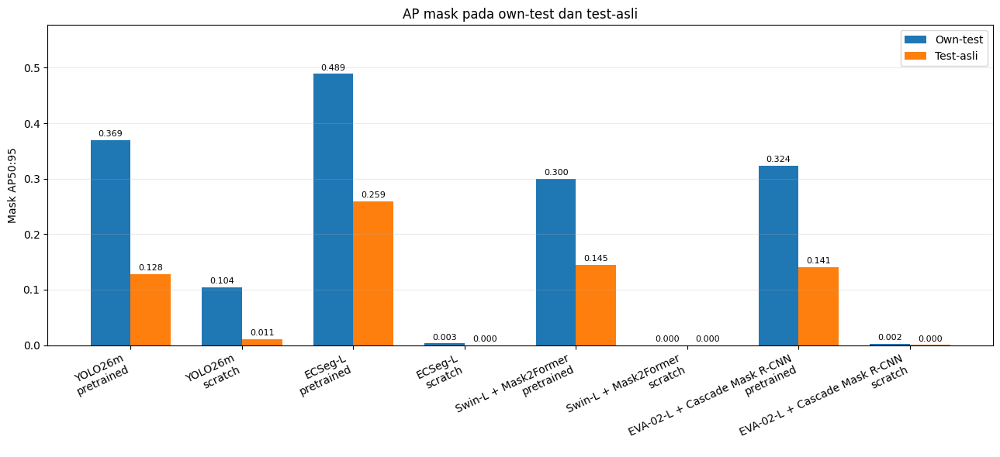

In [30]:
plot_data = domain_metrics.copy()
plot_data["Label model"] = (
    plot_data["Model"] + "\n" + plot_data["Inisialisasi"]
)

x = np.arange(len(plot_data))
width = 0.36

fig, ax = plt.subplots(figsize=(13, 6))
bars_own = ax.bar(
    x - width / 2,
    plot_data["AP50:95 own"],
    width,
    label="Own-test",
)
bars_original = ax.bar(
    x + width / 2,
    plot_data["AP50:95 test-asli"],
    width,
    label="Test-asli",
)

ax.set_title("AP mask pada own-test dan test-asli")
ax.set_ylabel("Mask AP50:95")
ax.set_xticks(x)
ax.set_xticklabels(plot_data["Label model"], rotation=25, ha="right")
ax.set_ylim(0, max(0.05, plot_data[
    ["AP50:95 own", "AP50:95 test-asli"]
].to_numpy().max() * 1.18))
ax.grid(axis="y", alpha=0.25)
ax.legend()

ax.bar_label(bars_own, fmt="%.3f", padding=2, fontsize=8)
ax.bar_label(bars_original, fmt="%.3f", padding=2, fontsize=8)

fig.tight_layout()
plt.show()

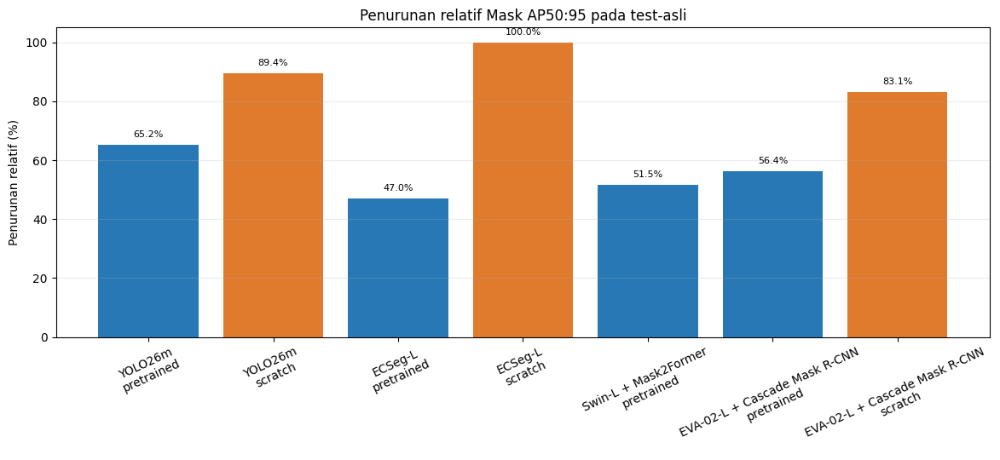

In [31]:
drop_data = domain_metrics.dropna(
    subset=["Penurunan relatif AP50:95 (%)"]
).copy()
drop_data["Label model"] = (
    drop_data["Model"] + "\n" + drop_data["Inisialisasi"]
)

fig, ax = plt.subplots(figsize=(12, 5.5))
bars = ax.bar(
    drop_data["Label model"],
    drop_data["Penurunan relatif AP50:95 (%)"],
    color=[
        "#2878B5" if arm == "pretrained" else "#E07A2D"
        for arm in drop_data["Inisialisasi"]
    ],
)

ax.set_title("Penurunan relatif Mask AP50:95 pada test-asli")
ax.set_ylabel("Penurunan relatif (%)")
ax.set_ylim(0, 105)
ax.grid(axis="y", alpha=0.25)
ax.tick_params(axis="x", rotation=25)

for bar, value in zip(bars, drop_data["Penurunan relatif AP50:95 (%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 2,
        f"{value:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8,
    )

fig.tight_layout()
plt.show()

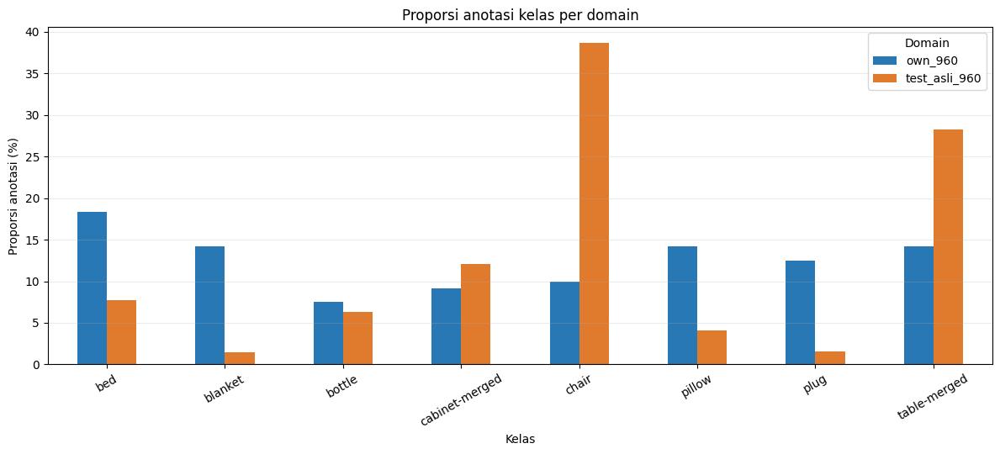

In [33]:
ax = class_percent.plot(
    kind="bar",
    figsize=(12, 5.5),
    color=["#2878B5", "#E07A2D"],
)

ax.set_title("Proporsi anotasi kelas per domain")
ax.set_ylabel("Proporsi anotasi (%)")
ax.set_xlabel("Kelas")
ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.25)
ax.legend(title="Domain")

plt.tight_layout()
plt.show()

Semua checkpoint pretrained mendapat AP50:95 lebih rendah pada test-asli dibanding own-test. Penurunan relatifnya adalah 65.2% untuk YOLO26m pretrained, 47.0% untuk ECSeg-L pretrained, 51.5% untuk Swin-L pretrained, dan 56.4% untuk EVA-02-L pretrained. Di antara keempatnya, ECSeg-L pretrained memiliki penurunan relatif terkecil pada run ini.

Checkpoint scratch memiliki skor rendah pada kedua domain. YOLO26m turun 89.4%, ECSeg-L turun dari 0.003 menjadi 0.000, Swin-L memperoleh AP 0 pada keduanya, dan EVA-02-L turun 83.1%.

Hasil ini menunjukkan adanya kesenjangan generalisasi antara dua dataset, tetapi tidak membuktikan penyebab visual tertentu. Foto tidak berpasangan, ukuran set berbeda jauh, komposisi kelas tidak seimbang, dan perbedaan anotasi juga mungkin berpengaruh. Perbandingan AP absolut antarkeluarga model perlu hati-hati karena evaluator dan implementasi modelnya berbeda.

# Lima Studi Kasus Kegagalan ECSeg-L

Inferensi per foto dan simpan mask ECSeg-L

In [24]:
from pathlib import Path
import gc
import json
import sys

import numpy as np
import torch
from pycocotools import mask as mask_utils

# Gunakan root yang ditemukan di Cell 1 agar tidak menggandakan
# reports/own_test_eval saat kernel berjalan dari folder notebook.
EC_ROOT = ROOT / "third_party/EdgeCrafter/ecdetseg"
EVAL_ROOT = ROOT / "reports/own_test_eval"
DOMAIN = EVAL_ROOT / "domain_shift/own_960"
IMAGE_DIR = DOMAIN / "images"
GT_PATH = DOMAIN / "ground_truth_things.json"
CHECKPOINT = ROOT / "reports/ecseg_l_k35_ws/checkpoints/best_ecseg_l_k35_ws.pth"
CASE_DIR = EVAL_ROOT / "failure_cases_ecseg_l"
CASE_DIR.mkdir(parents=True, exist_ok=True)

sys.path.insert(0, str(EC_ROOT))
from engine.core import YAMLConfig
from engine.solver import TASKS
import engine.solver.ec_solver as ec_solver_module

GT = json.loads(GT_PATH.read_text(encoding="utf-8"))

def run_ecseg_capture(size_hw=(640, 640), keep_ids=None):
    """Jalankan checkpoint ECSeg-L dan ambil prediksi instance per foto."""
    captured = {}

    def capture_evaluate(model, criterion, postprocessor, data_loader,
                         coco_evaluator, device):
        model.eval()
        with torch.inference_mode():
            for samples, targets in data_loader:
                outputs = model(samples.to(device))
                orig_sizes = torch.stack([t["orig_size"] for t in targets]).to(device)
                results = postprocessor(outputs, orig_sizes)
                for target, result in zip(targets, results):
                    image_id = int(target["image_id"].item())
                    if keep_ids is not None and image_id not in keep_ids:
                        continue
                    masks = result["masks"].detach().cpu().numpy()
                    labels = result["labels"].detach().cpu().numpy().astype(int)
                    scores = result["scores"].detach().cpu().numpy()
                    rows = []
                    for mask, label, score in zip(masks, labels, scores):
                        mask = np.squeeze(mask).astype(np.uint8)
                        if mask.ndim != 2:
                            continue
                        rle = mask_utils.encode(np.asfortranarray(mask))
                        rle["counts"] = rle["counts"].decode("ascii")
                        rows.append({"category_id": int(label), "score": float(score),
                                     "segmentation": rle})
                    captured[image_id] = rows
        # Evaluator tidak dipakai di fungsi capture ini; Cell 8 tetap menjadi
        # sumber metrik COCO utama dengan runner evaluasi standar.
        from types import SimpleNamespace
        evaluator_stub = SimpleNamespace(coco_eval={"segm": SimpleNamespace(eval={})})
        return {}, evaluator_stub

    cfg = YAMLConfig(str(EC_ROOT / "configs/ecseg/_eval/test_sendiri.yml"),
                     tuning=str(CHECKPOINT), device="cuda:0",
                     output_dir=str(CASE_DIR / f"capture_{size_hw[0]}x{size_hw[1]}"))
    # Override hanya dataset evaluasi; checkpoint dan postprocessor tetap sama.
    val_ds = cfg.yaml_cfg["val_dataloader"]["dataset"]
    val_ds["img_folder"] = str(IMAGE_DIR)
    val_ds["ann_file"] = str(GT_PATH)
    cfg.yaml_cfg["val_dataloader"]["total_batch_size"] = 1
    cfg.yaml_cfg["val_dataloader"]["num_workers"] = 0
    cfg.yaml_cfg["val_dataloader"]["dataset"]["transforms"]["ops"][0]["size"] = list(size_hw)
    cfg.yaml_cfg["eval_spatial_size"] = list(size_hw)

    # ECSolver.val memanggil fungsi ini setelah memuat checkpoint + loader.
    previous_evaluate = ec_solver_module.evaluate
    ec_solver_module.evaluate = capture_evaluate
    try:
        solver = TASKS["segmentation"](cfg)
        solver.val()
    finally:
        ec_solver_module.evaluate = previous_evaluate
        if "solver" in locals():
            del solver
        gc.collect()
        torch.cuda.empty_cache()
    return captured

predictions_640 = run_ecseg_capture((640, 640))
(CASE_DIR / "predictions_640.json").write_text(
    json.dumps({str(k): v for k, v in predictions_640.items()}), encoding="utf-8")
print(f"Prediksi tersimpan untuk {len(predictions_640)} foto.")


C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\third_party\EdgeCrafter\ecdetseg\engine\core\yaml_config.py:207: UserWarning: 'stop_epoch' was not correctly set for training transforms. Automatically adjusted to: epochs - 2.
  warnings.warn(



Trying to load pretrained ViT weights from https://github.com/capsule2077/edgecrafter/releases/download/edgecrafterv1/ecseg_vits.pth. If this fails, please download the model manually.
If you have already downloaded the model, please check that `weights_path` is correct and the file exists.
✅ Pretrained ViT weights loaded successfully!
📦 Weights downloaded to: C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\third_party\EdgeCrafter\ecdetseg\ecvits
Tuning checkpoint from C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\ecseg_l_k35_ws\checkpoints\best_ecseg_l_k35_ws.pth
Load model.state_dict, {'missed': [], 'unmatched': []}
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!
Prediksi tersimpan untuk 40 foto.


Skor per foto, pilih lima kasus, dan buat panel

In [25]:
from collections import defaultdict
from scipy.optimize import linear_sum_assignment
from pycocotools import mask as mask_utils
from PIL import Image
import matplotlib.pyplot as plt
import pandas as pd

image_by_id = {im["id"]: im for im in GT["images"]}
anns_by_image = defaultdict(list)
for ann in GT["annotations"]:
    anns_by_image[ann["image_id"]].append(ann)

def decode_coco_mask(segmentation, height, width):
    if isinstance(segmentation, dict):
        rle = dict(segmentation)
        if isinstance(rle.get("counts"), str):
            rle["counts"] = rle["counts"].encode("ascii")
        return mask_utils.decode(rle).astype(bool)
    rles = mask_utils.frPyObjects(segmentation, height, width)
    return np.any(mask_utils.decode(rles), axis=2)

def analyze_image(image_id, pred_rows, score_thr=0.05):
    im = image_by_id[image_id]
    h, w = im["height"], im["width"]
    gt_rows = anns_by_image[image_id]
    gt_masks = [decode_coco_mask(a["segmentation"], h, w) for a in gt_rows]
    gt_labels = np.array([a["category_id"] for a in gt_rows], dtype=int)
    preds = [p for p in pred_rows if p["score"] >= score_thr]
    pred_masks = [decode_coco_mask(p["segmentation"], h, w) for p in preds]
    pred_labels = np.array([p["category_id"] for p in preds], dtype=int)
    iou = np.zeros((len(gt_rows), len(preds)), dtype=float)
    for gi, gm in enumerate(gt_masks):
        for pi, pm in enumerate(pred_masks):
            union = np.logical_or(gm, pm).sum()
            iou[gi, pi] = np.logical_and(gm, pm).sum() / union if union else 0.0
    same = (gt_labels[:, None] == pred_labels[None, :]) if preds else np.zeros_like(iou, bool)
    same_iou = np.where(same, iou, 0.0)
    matched_gt = set()
    if len(gt_rows) and len(preds):
        rr, cc = linear_sum_assignment(1.0 - same_iou)
        matched_gt = {int(r) for r, c in zip(rr, cc) if same_iou[r, c] >= 0.50}
    failures = []
    for gi, ann in enumerate(gt_rows):
        if gi in matched_gt:
            continue
        best_same = float(same_iou[gi].max()) if len(preds) else 0.0
        best_any = float(iou[gi].max()) if len(preds) else 0.0
        if best_any >= 0.50 and best_same < 0.50:
            kind = "wrong-class candidate"
        elif best_same < 0.10:
            kind = "missed / near-missed object"
        else:
            kind = "mask overlap below 0.50"
        failures.append({"category_id": ann["category_id"], "type": kind,
                         "best_same_class_IoU": best_same, "best_any_class_IoU": best_any})
    return failures, gt_masks, pred_masks, gt_labels, pred_labels, preds

per_image = []
for image_id, im in image_by_id.items():
    failures, *_ = analyze_image(image_id, predictions_640.get(image_id, []))
    if failures:
        per_image.append({"image_id": image_id, "file_name": im["file_name"],
                          "n_gt": len(anns_by_image[image_id]),
                          "n_failed_gt": len(failures),
                          "mean_best_same_IoU": np.mean([f["best_same_class_IoU"] for f in failures]),
                          "failure_types": "; ".join(f["type"] for f in failures),
                          "failed_classes": ", ".join(str(f["category_id"]) for f in failures)})

case_table = pd.DataFrame(per_image).sort_values(
    ["n_failed_gt", "mean_best_same_IoU"], ascending=[False, True]).head(5).reset_index(drop=True)
if len(case_table) < 5:
    raise RuntimeError(f"Hanya {len(case_table)} foto memiliki GT gagal; jangan membuat lima kasus semu.")
case_table.to_csv(CASE_DIR / "five_cases.csv", index=False)
case_table


,image_id,file_name,n_gt,n_failed_gt,mean_best_same_IoU,failure_types,failed_classes
0,14,IMG_20261123_095054_328_jpg.rf.86e0fb946b0db35...,4,2,0.000000,wrong-class candidate; wrong-class candidate,"3, 3"
1,30,IMG_20261123_095545_640_jpg.rf.b51d912f094a31f...,5,1,0.000000,wrong-class candidate,3
2,2,IMG_20261123_095057_707_jpg.rf.e928cbd317e7897...,5,1,0.065135,missed / near-missed object,29
3,11,IMG_20261123_095227_470_jpg.rf.fe96da8a5e389c2...,6,1,0.084901,missed / near-missed object,29
4,7,IMG_20261123_095143_354_jpg.rf.c3de64f310692e9...,3,1,0.185430,mask overlap below 0.50,23


Eksperimen kecil pada lima foto

Kasus 1: IMG_20261123_095054_328_jpg.rf.86e0fb946b0db35c695e4867446195b5.jpg
  Kelas GT bermask: bottle: 1 anotasi, 257781 piksel mask, chair: 1 anotasi, 82418 piksel mask, floor-other-merged: 1 anotasi, 51715 piksel mask, wall-other-merged: 1 anotasi, 271610 piksel mask
  Kelas prediksi conf ≥ 0.05: bottle: 1, cabinet-merged: 3, ceiling-merged: 1, chair: 2, counter: 6, door-stuff: 1, fire-extinguisher: 1, floor-other-merged: 12, floor-wood: 1, food-other-merged: 1, pan: 1, person: 1, potted plant: 1, rug-merged: 1, stairs: 2, table-merged: 13, wall-brick: 1, wall-other-merged: 17, window-blind: 2, window-other: 1


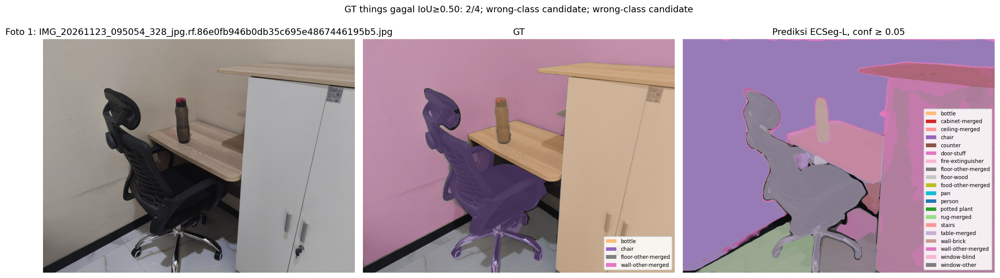

Kasus 2: IMG_20261123_095545_640_jpg.rf.b51d912f094a31f12d070567342ad671.jpg
  Kelas GT bermask: bottle: 1 anotasi, 2965 piksel mask, cabinet-merged: 1 anotasi, 173868 piksel mask, chair: 1 anotasi, 62418 piksel mask, floor-other-merged: 1 anotasi, 83220 piksel mask, plug: 1 anotasi, 3207 piksel mask, table-merged: 1 anotasi, 8854 piksel mask, wall-other-merged: 1 anotasi, 331969 piksel mask
  Kelas prediksi conf ≥ 0.05: bed: 5, blanket: 5, box: 1, cabinet-merged: 1, ceiling-merged: 4, chair: 3, couch: 1, counter: 2, door-stuff: 1, floor-other-merged: 17, floor-wood: 4, light: 1, pan: 1, paper: 1, person: 4, pillow: 1, plug: 4, rug-merged: 2, stairs: 3, table-merged: 7, wall-other-merged: 24, window-blind: 4


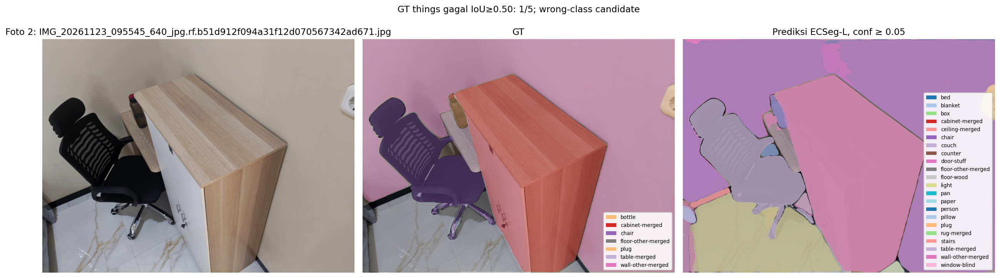

Kasus 3: IMG_20261123_095057_707_jpg.rf.e928cbd317e7897646ae201c827adbfb.jpg
  Kelas GT bermask: bottle: 1 anotasi, 4864 piksel mask, cabinet-merged: 1 anotasi, 213074 piksel mask, chair: 1 anotasi, 95542 piksel mask, floor-other-merged: 1 anotasi, 59887 piksel mask, table-merged: 1 anotasi, 26590 piksel mask, wall-other-merged: 1 anotasi, 256809 piksel mask
  Kelas prediksi conf ≥ 0.05: bed: 2, book: 8, bottle: 2, box: 1, cabinet-merged: 4, chair: 2, couch: 2, counter: 7, door-stuff: 2, floor-other-merged: 11, floor-wood: 2, food-other-merged: 1, pan: 1, paper: 1, potted plant: 1, rug-merged: 2, stairs: 3, table-merged: 10, wall-other-merged: 25, window-blind: 3


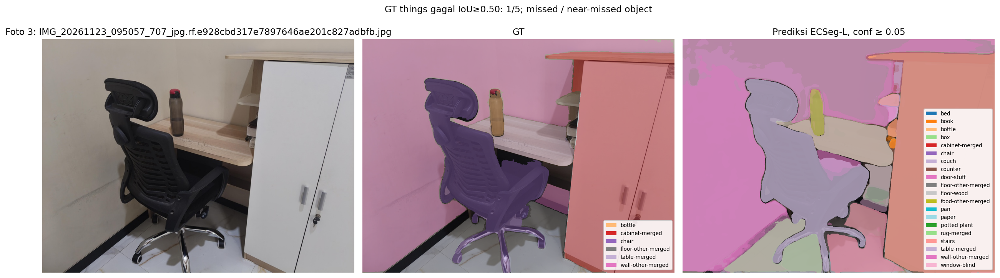

Kasus 4: IMG_20261123_095227_470_jpg.rf.fe96da8a5e389c2e07b1763c257ed91c.jpg
  Kelas GT bermask: cabinet-merged: 1 anotasi, 95855 piksel mask, chair: 1 anotasi, 38147 piksel mask, door-stuff: 1 anotasi, 160894 piksel mask, plug: 1 anotasi, 2199 piksel mask, table-merged: 1 anotasi, 16275 piksel mask, wall-other-merged: 1 anotasi, 543350 piksel mask
  Kelas prediksi conf ≥ 0.05: bed: 3, box: 2, cabinet-merged: 3, chair: 3, counter: 4, door-stuff: 2, fire-extinguisher: 1, floor-other-merged: 11, floor-wood: 1, light: 1, pan: 1, plug: 3, rug-merged: 1, stairs: 2, stove-merged: 1, table-merged: 11, toy: 1, wall-other-merged: 13, window-blind: 1, window-other: 1


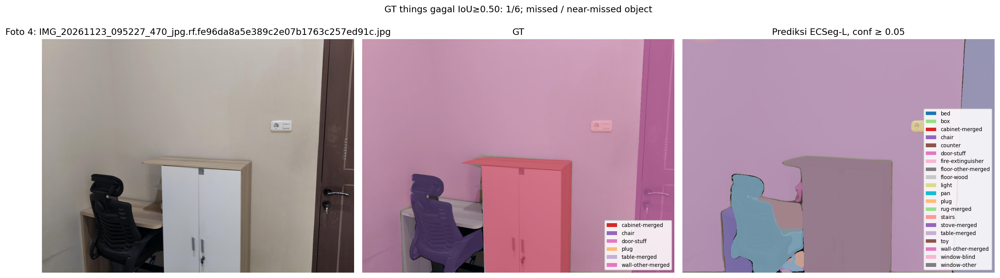

Kasus 5: IMG_20261123_095143_354_jpg.rf.c3de64f310692e9f909ec9f692c1c782.jpg
  Kelas GT bermask: bed: 1 anotasi, 28078 piksel mask, plug: 1 anotasi, 1393 piksel mask, wall-other-merged: 1 anotasi, 596812 piksel mask, window-blind: 1 anotasi, 60981 piksel mask
  Kelas prediksi conf ≥ 0.05: bed: 1, blanket: 2, box: 1, ceiling-merged: 1, chair: 1, cup: 1, door-stuff: 1, floor-other-merged: 3, light: 4, pillow: 1, plug: 9, potted plant: 1, rug-merged: 1, stairs: 2, table-merged: 2, toy: 1, wall-other-merged: 22, window-blind: 3, window-other: 2


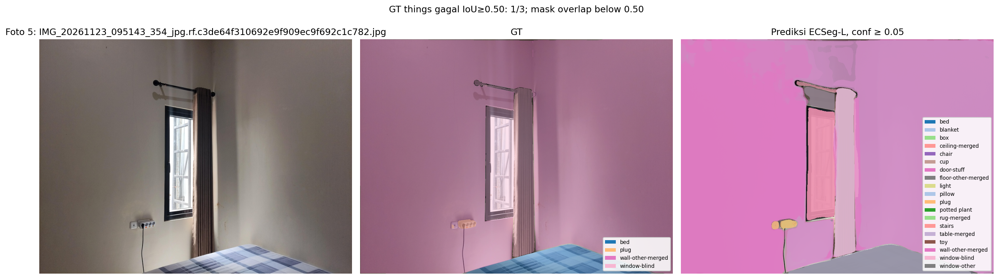

In [27]:
# Simpan dan tampilkan satu panel per kasus: foto asli, GT, dan prediksi ECSeg-L.
from IPython.display import display
from collections import Counter
from matplotlib.patches import Patch

GT_FULL = json.loads(
    (EVAL_ROOT / "ground_truth_35.json").read_text(encoding="utf-8")
)

full_image_by_id = {im["id"]: im for im in GT_FULL["images"]}
full_anns_by_image = defaultdict(list)
for ann in GT_FULL["annotations"]:
    full_anns_by_image[ann["image_id"]].append(ann)

class_names = {c["id"]: c["name"] for c in GT_FULL["categories"]}


def decode_full_gt_mask_at_eval_size(ann, target_meta):
    """Decode poligon GT sumber setelah koordinatnya diskalakan ke own_960."""
    source_meta = full_image_by_id[ann["image_id"]]
    sx = target_meta["width"] / source_meta["width"]
    sy = target_meta["height"] / source_meta["height"]

    segmentation = ann["segmentation"]
    if not isinstance(segmentation, list):
        raise TypeError(
            f"GT bukan poligon untuk annotation_id={ann['id']}"
        )

    scaled = [
        [
            coord * (sx if i % 2 == 0 else sy)
            for i, coord in enumerate(poly)
        ]
        for poly in segmentation
    ]
    return decode_coco_mask(
        scaled, target_meta["height"], target_meta["width"]
    )


def make_overlay(image, masks, labels, alpha=0.40):
    """Warnai mask per kelas tanpa mengubah array gambar asli."""
    overlay = image.copy()
    visible_labels = set()
    mask_pixels_by_label = Counter()

    for mask, label in zip(masks, labels):
        label = int(label)
        pixels = np.asarray(mask, dtype=bool)
        pixel_count = int(pixels.sum())
        if pixel_count == 0:
            continue

        visible_labels.add(label)
        mask_pixels_by_label[label] += pixel_count

        color = (
            np.asarray(plt.get_cmap("tab20")(label % 20)[:3]) * 255
        ).astype(np.uint8)

        overlay[pixels] = (
            (1 - alpha) * overlay[pixels].astype(np.float32)
            + alpha * color.astype(np.float32)
        ).astype(np.uint8)

    return overlay, sorted(visible_labels), mask_pixels_by_label


for rank, row in case_table.iterrows():
    image_id = int(row.image_id)
    im_meta = image_by_id[image_id]  # metadata gambar own_960
    image_path = IMAGE_DIR / im_meta["file_name"]
    image = np.asarray(Image.open(image_path).convert("RGB"))

    _, _, pred_masks, _, pred_labels, preds = analyze_image(
        image_id, predictions_640.get(image_id, [])
    )

    # Mask GT dibuat dari seluruh anotasi yang tersedia untuk foto ini.
    full_gt_anns = full_anns_by_image.get(image_id, [])
    full_gt_masks = [
        decode_full_gt_mask_at_eval_size(ann, im_meta)
        for ann in full_gt_anns
    ]
    full_gt_labels = [
        int(ann["category_id"]) for ann in full_gt_anns
    ]

    gt_overlay, gt_visible_labels, gt_pixel_counts = make_overlay(
        image, full_gt_masks, full_gt_labels
    )
    pred_overlay, pred_visible_labels, pred_pixel_counts = make_overlay(
        image, pred_masks, pred_labels
    )

    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    axes[0].imshow(image)
    axes[0].set_title(f"Foto {rank + 1}: {im_meta['file_name']}")

    axes[1].imshow(gt_overlay)
    axes[1].set_title("GT")

    axes[2].imshow(pred_overlay)
    axes[2].set_title("Prediksi ECSeg-L, conf ≥ 0.05")

    for ax, visible_labels in [
        (axes[1], gt_visible_labels),
        (axes[2], pred_visible_labels),
    ]:
        handles = [
            Patch(
                facecolor=plt.get_cmap("tab20")(label % 20),
                label=class_names.get(label, f"ID {label}"),
            )
            for label in visible_labels
        ]
        if handles:
            ax.legend(
                handles=handles,
                loc="lower right",
                fontsize=7,
                framealpha=0.88,
            )
        else:
            ax.text(
                0.02, 0.02, "Tidak ada mask",
                transform=ax.transAxes,
                color="white",
                fontsize=9,
                bbox={"facecolor": "black", "alpha": 0.6, "pad": 3},
            )

    for ax in axes:
        ax.axis("off")

    fig.suptitle(
        f"GT things gagal IoU≥0.50: "
        f"{row.n_failed_gt}/{row.n_gt}; {row.failure_types}"
    )
    fig.tight_layout()

    panel_path = CASE_DIR / f"case_{rank + 1}_{image_id}.png"
    fig.savefig(panel_path, dpi=140, bbox_inches="tight")
    plt.close(fig)

    gt_class_counts = Counter(
        class_names.get(label, f"ID {label}")
        for label in gt_visible_labels
    )
    gt_summary = ", ".join(
        f"{name}: {gt_class_counts[name]} anotasi, "
        f"{gt_pixel_counts[label]} piksel mask"
        for label in gt_visible_labels
        for name in [class_names.get(label, f"ID {label}")]
    ) or "tidak ada mask GT yang terdekode"

    pred_class_counts = Counter(
        int(pred["category_id"]) for pred in preds
    )
    pred_summary = ", ".join(
        f"{class_names.get(label, f'ID {label}')}: {count}"
        for label, count in sorted(pred_class_counts.items())
    ) or "tidak ada prediksi di atas ambang"

    print(f"Kasus {rank + 1}: {im_meta['file_name']}")
    print(f"  Kelas GT bermask: {gt_summary}")
    print(f"  Kelas prediksi conf ≥ 0.05: {pred_summary}")

    with Image.open(panel_path) as panel:
        display(panel.copy())

In [23]:
selected_ids = set(case_table["image_id"].astype(int))
predictions_native = run_ecseg_capture((480, 640), keep_ids=selected_ids)

def matched_recall(image_id, pred_rows):
    failures, *_ = analyze_image(image_id, pred_rows, score_thr=0.05)
    n_gt = len(anns_by_image[image_id])
    return {"n_gt": n_gt, "n_failed": len(failures),
            "n_matched": n_gt - len(failures),
            "mean_failure_best_iou": (np.mean([x["best_same_class_IoU"] for x in failures])
                                       if failures else np.nan)}

comparison = []
for image_id in sorted(selected_ids):
    for condition, pred_set in [("square_640", predictions_640),
                                ("native_480x640", predictions_native)]:
        comparison.append({"image_id": image_id, "condition": condition,
                           **matched_recall(image_id, pred_set.get(image_id, []))})
experiment = pd.DataFrame(comparison)
experiment.to_csv(CASE_DIR / "aspect_experiment.csv", index=False)
experiment.pivot(index="image_id", columns="condition",
                 values=["n_matched", "n_failed", "mean_failure_best_iou"])


C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\third_party\EdgeCrafter\ecdetseg\engine\core\yaml_config.py:207: UserWarning: 'stop_epoch' was not correctly set for training transforms. Automatically adjusted to: epochs - 2.
  warnings.warn(



Trying to load pretrained ViT weights from https://github.com/capsule2077/edgecrafter/releases/download/edgecrafterv1/ecseg_vits.pth. If this fails, please download the model manually.
If you have already downloaded the model, please check that `weights_path` is correct and the file exists.
✅ Pretrained ViT weights loaded successfully!
📦 Weights downloaded to: C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\third_party\EdgeCrafter\ecdetseg\ecvits
Tuning checkpoint from C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\ecseg_l_k35_ws\checkpoints\best_ecseg_l_k35_ws.pth
Load model.state_dict, {'missed': [], 'unmatched': ['decoder.anchors', 'decoder.valid_mask']}
loading annotations into memory...
Done (t=0.01s)
creating index...
index created!


n_matched                  n_failed             \
condition native_480x640 square_640 native_480x640 square_640   
image_id                                                        
2                    5.0        4.0            0.0        1.0   
7                    2.0        2.0            1.0        1.0   
11                   5.0        5.0            1.0        1.0   
14                   2.0        2.0            2.0        2.0   
30                   5.0        4.0            0.0        1.0   

          mean_failure_best_iou             
condition        native_480x640 square_640  
image_id                                    
2                           NaN   0.065135  
7                      0.190476   0.185430  
11                     0.087255   0.084901  
14                     0.000000   0.000000  
30                          NaN   0.000000

Pada eksperimen berpasangan, input 480×640 menghasilkan satu tambahan GT yang terpasang pada foto `image_id` 2 dan satu pada `image_id` 30. Keduanya berubah dari 4/5 menjadi 5/5 GT matched. Foto 7 tetap 2/3, dengan IoU kegagalan berubah sedikit dari 0.1854 menjadi 0.1905. Foto 11 tetap 5/6, IoU berubah dari 0.0849 menjadi 0.0873. Foto 14 tetap 2/4 dengan dua kandidat salah kelas.

Hasil ini memberi dukungan terbatas bahwa mempertahankan rasio aspek dapat membantu sebagian kasus terpilih. Perubahannya hanya terlihat pada dua dari lima foto dan tidak memperbaiki semua jenis kegagalan. Karena lima foto dipilih dari kasus terburuk pada kondisi 640×640, eksperimen ini bersifat eksploratif dan tidak dapat digeneralisasi ke seluruh test set.

# Demo

In [39]:
CONF_THRESHOLD = 0.2

Resolusi asli: 3120 × 4160
Resolusi inferensi: 720 × 960


C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\third_party\EdgeCrafter\ecdetseg\engine\core\yaml_config.py:207: UserWarning: 'stop_epoch' was not correctly set for training transforms. Automatically adjusted to: epochs - 2.
  warnings.warn(



YOLO26m pretrained: 34 mask pada conf ≥ 0.05
  bed: 1 mask, max confidence 0.110
  chair: 3 mask, max confidence 0.786
  door-stuff: 1 mask, max confidence 0.081
  floor-other-merged: 7 mask, max confidence 0.127
  floor-wood: 2 mask, max confidence 0.084
  paper: 2 mask, max confidence 0.080
  plug: 1 mask, max confidence 0.088
  stairs: 1 mask, max confidence 0.065
  table-merged: 2 mask, max confidence 0.551
  wall-other-merged: 8 mask, max confidence 0.479
  window-blind: 2 mask, max confidence 0.328
  window-other: 4 mask, max confidence 0.463

ECSeg-L pretrained: 28 mask pada conf ≥ 0.05
  box: 1 mask, max confidence 0.247
  cabinet-merged: 3 mask, max confidence 0.369
  chair: 2 mask, max confidence 0.911
  door-stuff: 1 mask, max confidence 0.356
  floor-other-merged: 2 mask, max confidence 0.259
  floor-wood: 5 mask, max confidence 0.891
  person: 1 mask, max confidence 0.573
  table-merged: 1 mask, max confidence 0.867
  wall-brick: 1 mask, max confidence 0.202
  wall-other-

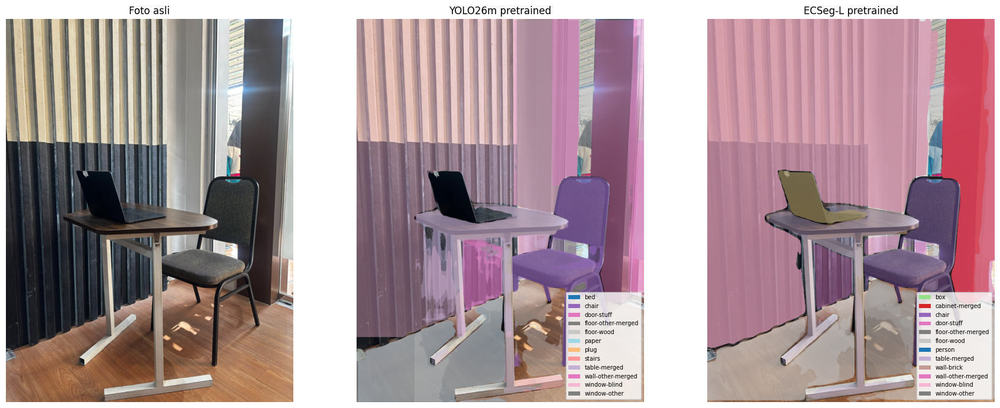


Hasil gambar disimpan ke: C:\Users\Rafli\Documents\kodin\python\kompis\Minggu 13\reports\own_test_eval\demo_yolo26_ecsegL.png


In [41]:
from pathlib import Path
from collections import Counter
import gc
import json
import sys

import numpy as np
import torch
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from PIL import Image
from ultralytics import YOLO

# Temukan root proyek.
cwd = Path.cwd().resolve()
ROOT = next(
    (
        p for p in (cwd, *cwd.parents)
        if (p / "reports/own_test_eval/ground_truth_35.json").exists()
    ),
    None,
)
if ROOT is None:
    raise FileNotFoundError("Tidak menemukan root proyek.")

IMAGE_PATH = (
    ROOT / "reports/own_test_eval/"
    "WhatsApp Image 2026-11-25 at 13.21.04.jpeg"
)
YOLO_CHECKPOINT = ROOT / "local_runs/k35_m_pf0/weights/best.pt"
ECSEG_CHECKPOINT = (
    ROOT / "reports/ecseg_l_k35_ws/checkpoints/best_ecseg_l_k35_ws.pth"
)
EC_ROOT = ROOT / "third_party/EdgeCrafter/ecdetseg"
ECSEG_CONFIG = EC_ROOT / "configs/ecseg/_eval/test_sendiri.yml"
CLASSSPACE_PATH = ROOT / "reports/own_test_eval/classspace.json"
OUTPUT_PATH = ROOT / "reports/own_test_eval/demo_yolo26_ecsegL.png"

for path in [
    IMAGE_PATH, YOLO_CHECKPOINT, ECSEG_CHECKPOINT,
    ECSEG_CONFIG, CLASSSPACE_PATH,
]:
    if not path.exists():
        raise FileNotFoundError(f"File tidak ditemukan: {path}")

classspace = json.loads(CLASSSPACE_PATH.read_text(encoding="utf-8"))
class_names = {
    class_id: name
    for class_id, name in enumerate(classspace["names"])
}

# Batasi ukuran gambar sebelum inferensi agar mask keluaran tidak terlalu besar.
image_original = Image.open(IMAGE_PATH).convert("RGB")
original_width, original_height = image_original.size
max_side = 960
scale = min(1.0, max_side / max(original_width, original_height))
image_size = (
    max(1, round(original_width * scale)),
    max(1, round(original_height * scale)),
)
image = image_original.resize(image_size, Image.Resampling.LANCZOS)
image_np = np.asarray(image)
height, width = image_np.shape[:2]

print(f"Resolusi asli: {original_width} × {original_height}")
print(f"Resolusi inferensi: {width} × {height}")

CONF_THRESHOLD = 0.05
device = 0 if torch.cuda.is_available() else "cpu"


def fit_mask_to_image(mask):
    """Pastikan mask berukuran sama dengan gambar yang ditampilkan."""
    mask = np.asarray(mask, dtype=bool)
    if mask.shape != (height, width):
        mask_img = Image.fromarray(mask.astype(np.uint8) * 255)
        mask = np.asarray(
            mask_img.resize(image.size, Image.Resampling.NEAREST)
        ) > 0
    return mask


def make_overlay(image_array, predictions):
    """Predictions berisi tuple (class_id, score, mask)."""
    overlay = image_array.copy()

    for class_id, score, mask in predictions:
        color = (
            np.asarray(plt.get_cmap("tab20")(class_id % 20)[:3]) * 255
        ).astype(np.uint8)
        pixels = fit_mask_to_image(mask)
        overlay[pixels] = (
            0.60 * overlay[pixels].astype(np.float32)
            + 0.40 * color.astype(np.float32)
        ).astype(np.uint8)

    return overlay


def print_summary(model_name, predictions):
    print(f"\n{model_name}: {len(predictions)} mask pada conf ≥ {CONF_THRESHOLD}")
    counts = Counter(class_id for class_id, _, _ in predictions)
    for class_id, count in sorted(counts.items()):
        scores = [
            score for pred_class, score, _ in predictions
            if pred_class == class_id
        ]
        print(
            f"  {class_names.get(class_id, f'ID {class_id}')}: "
            f"{count} mask, max confidence {max(scores):.3f}"
        )


# 1) YOLO26m pretrained.
yolo_model = YOLO(str(YOLO_CHECKPOINT))
yolo_result = yolo_model.predict(
    source=image_np,
    imgsz=640,
    conf=CONF_THRESHOLD,
    iou=0.7,
    max_det=100,
    device=device,
    retina_masks=True,
    verbose=False,
)[0]

yolo_predictions = []
if yolo_result.masks is not None and yolo_result.boxes is not None:
    yolo_masks = yolo_result.masks.data.cpu().numpy()
    yolo_labels = yolo_result.boxes.cls.cpu().numpy().astype(int)
    yolo_scores = yolo_result.boxes.conf.cpu().numpy()

    for mask, label, score in zip(yolo_masks, yolo_labels, yolo_scores):
        yolo_predictions.append(
            (int(label), float(score), fit_mask_to_image(mask > 0.5))
        )

del yolo_model, yolo_result
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# 2) ECSeg-L pretrained.
sys.path.insert(0, str(EC_ROOT))
from tools.inference.torch_inf import build_model, ECInferencer

torch_device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
ecseg_model, input_size, task = build_model(
    str(ECSEG_CONFIG),
    str(ECSEG_CHECKPOINT),
    torch_device,
)
ecseg_inferencer = ECInferencer(
    model=ecseg_model,
    task=task,
    device=torch_device,
    size=input_size,
    thresh=0.2,
)

ecseg_results = ecseg_inferencer.infer(image)
ecseg_predictions = [
    (
        int(result.label),
        float(result.score),
        fit_mask_to_image(result.mask),
    )
    for result in ecseg_results
]

del ecseg_inferencer, ecseg_model, ecseg_results
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

# Cetak kelas dan skor agar hasilnya mudah diperiksa.
print_summary("YOLO26m pretrained", yolo_predictions)
print_summary("ECSeg-L pretrained", ecseg_predictions)

# Tampilkan foto dan dua hasil segmentasi.
yolo_overlay = make_overlay(image_np, yolo_predictions)
ecseg_overlay = make_overlay(image_np, ecseg_predictions)

fig, axes = plt.subplots(1, 3, figsize=(18, 7))
axes[0].imshow(image_np)
axes[0].set_title("Foto asli")
axes[1].imshow(yolo_overlay)
axes[1].set_title("YOLO26m pretrained")
axes[2].imshow(ecseg_overlay)
axes[2].set_title("ECSeg-L pretrained")

for ax, predictions in [
    (axes[1], yolo_predictions),
    (axes[2], ecseg_predictions),
]:
    labels = sorted({class_id for class_id, _, _ in predictions})
    handles = [
        Patch(
            facecolor=plt.get_cmap("tab20")(class_id % 20),
            label=class_names.get(class_id, f"ID {class_id}"),
        )
        for class_id in labels
    ]
    if handles:
        ax.legend(handles=handles, loc="lower right", fontsize=7)
    ax.axis("off")

axes[0].axis("off")
fig.tight_layout()
fig.savefig(OUTPUT_PATH, dpi=150, bbox_inches="tight")
plt.show()

print(f"\nHasil gambar disimpan ke: {OUTPUT_PATH}")